# Estimating an integral, then checking its uncertainty

We want the integral of $x^2$ from zero to one. Calculus gives $1/3$, which
provides an independent reference. Instead of using that answer in the
calculation, we will sample locations, average their heights, and examine
repeated experiments.

You need basic Python functions, averages, square roots, and the meaning of a
definite integral. Run this notebook from the repository after
`uv sync --locked --all-extras --dev`. Every cell runs offline. The numerical
package has no runtime dependencies; Matplotlib is used only for presentation.
The examples are authored teaching material and have not been learner-piloted.


In [1]:
import math

import matplotlib.pyplot as plt

from quantchapter_monte_carlo import __version__, convergence_experiment, integrate

print(f"Monte Carlo Lab {__version__} | seeded pseudorandom illustration")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})

Monte Carlo Lab 0.1.0 | seeded pseudorandom illustration


## Width times average height

First use a function whose answer does not depend on chance. If $f(x)=7$ on
$[2,5]$, every sampled height is seven. The interval width is three, so the
integral is $3\times7=21$. This checks the width factor before we introduce
varying observations.


In [2]:
constant = integrate(lambda x: 7.0, 2.0, 5.0, samples=20, seed=2026)
assert constant.estimate == 21.0
assert constant.standard_error == 0.0
print(
    f"Constant integral: {constant.estimate:g}; sampled standard error: {constant.standard_error:g}"
)

Constant integral: 21; sampled standard error: 0


For a general interval $[a,b]$, choose independent uniform locations
$X_1,\ldots,X_n$ and record $Y_i=f(X_i)$. Uniform means that equal-length
subintervals have equal probability. The sampled average is
$\overline Y=(Y_1+\cdots+Y_n)/n$, and the integral estimate is
$\widehat I=(b-a)\overline Y$. The average height times width has the right
units and is unbiased under the ideal independent uniform-sampling model.
Unbiased describes repeated experiments; it does not promise an exact run.

Now use $x^2$ on $[0,1]$. The implementation owns a local `Random(seed)` stream.
Repeating the seed reproduces a run in this Python environment. Exact binary
identity across different Python versions or platforms is not promised.


In [3]:
result = integrate(lambda x: x * x, 0.0, 1.0, samples=10_000, seed=2026)
truth = 1 / 3
print(f"Estimate: {result.estimate:.6f}")
print(f"Exact integral: {truth:.6f}")
print(f"Absolute error: {abs(result.estimate - truth):.6f}")

Estimate: 0.327411
Exact integral: 0.333333
Absolute error: 0.005923


## Spread of observations and uncertainty of an average

The standard deviation of individual heights is different from the uncertainty
of their average. Estimate the height variance with

$$s^2=\frac{\sum_{i=1}^n(Y_i-\overline Y)^2}{n-1}.$$

The $n-1$ divisor accounts for using these observations to estimate their own
mean. The integral's estimated standard error is $(b-a)s/\sqrt n$.
For a nominal 95% interval, the package uses
$\widehat I\pm z\widehat{\mathrm{SE}}$ with the normal quantile $z\approx1.96$.
This is a central-limit approximation. It has no guaranteed finite-sample
coverage, particularly for small samples or rare influential regions.


In [4]:
print(f"Estimated standard error: {result.standard_error:.6f}")
print(
    f"Approximate 95% normal interval: [{result.confidence_low:.6f}, {result.confidence_high:.6f}]"
)
covered = result.confidence_low <= truth <= result.confidence_high
print(f"This interval contains the reference: {covered}")

Estimated standard error: 0.002962
Approximate 95% normal interval: [0.321606, 0.333215]
This interval contains the reference: False


A 95% procedure is allowed to miss the target. Its confidence level concerns
repetition under the model, not a posterior probability for a fixed integral.
Even zero observed standard error does not prove exactness: a narrow nonzero
region may have been missed by all samples.

As a check, what happens for $f(x)=-2$ on $[3,8]$? The width is five, so the
integral is $5(-2)=-10$. Every sampled height coincides, so its standard error
is zero. A negative estimate is valid; a negative standard error is not.


In [5]:
check = integrate(lambda x: -2.0, 3.0, 8.0, samples=20, seed=2026)
assert check.estimate == -10.0 and check.standard_error == 0.0
print(f"Transfer check: integral = {check.estimate:g}, standard error = {check.standard_error:g}")

Transfer check: integral = -10, standard error = 0


## More samples: compare all prescribed replications

A single path's absolute error need not decrease every time samples increase.
Instead, prescribe sample counts and repeat each experiment. Here every size
uses 80 distinct consecutive seeds, beginning at 2026. No run is discarded.

For $x^2$ on $[0,1]$, the height variance is
$\operatorname{Var}(X^2)=1/5-(1/3)^2=4/45$. The theoretical standard error is
$\sqrt{4/(45n)}$. Quadrupling $n$ halves that theoretical error. Empirical root
mean squared error uses every estimate's deviation from the known $1/3$ value.
It has finite-replication noise, so it need not equal the theoretical curve.


In [6]:
points = convergence_experiment(lambda x: x * x, 0.0, 1.0, exact=truth, seed=2026)
print(" samples   empirical RMSE   mean estimated SE   interval coverage")
for point in points:
    print(
        f"{point.samples:8d}   {point.root_mean_squared_error:.6f}         "
        f"{point.mean_standard_error:.6f}           {point.empirical_coverage:.1%}"
    )

 samples   empirical RMSE   mean estimated SE   interval coverage
     100   0.030936         0.029926           95.0%
     400   0.016483         0.014850           91.2%
    1600   0.006718         0.007449           95.0%
    6400   0.003701         0.003727           96.2%


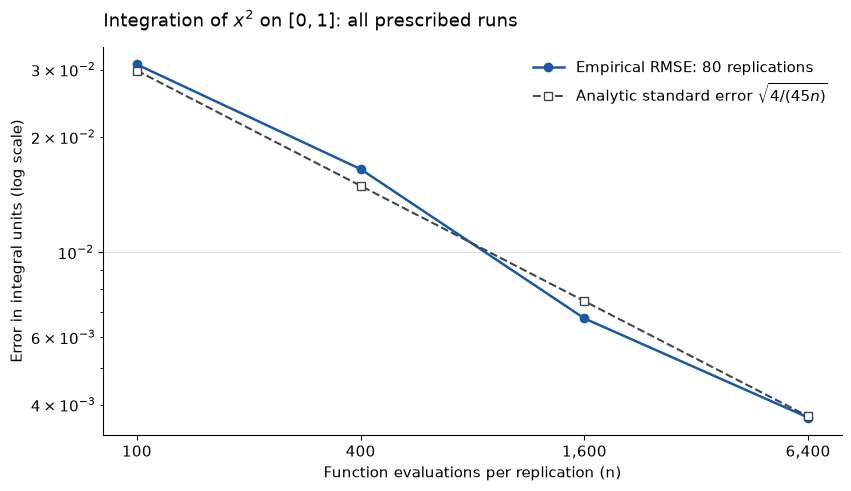

In [7]:
counts = [point.samples for point in points]
figure, axes = plt.subplots(figsize=(8.4, 4.8), layout="constrained")
axes.loglog(
    counts,
    [point.root_mean_squared_error for point in points],
    color="#1959a6",
    marker="o",
    linewidth=1.8,
    label="Empirical RMSE: 80 replications",
)
axes.loglog(
    counts,
    [math.sqrt(4 / (45 * count)) for count in counts],
    color="#3f4650",
    marker="s",
    markerfacecolor="white",
    linestyle="--",
    linewidth=1.5,
    label=r"Analytic standard error $\sqrt{4/(45n)}$",
)
axes.set_title(r"Integration of $x^2$ on $[0,1]$: all prescribed runs", loc="left", pad=14)
axes.set_xlabel("Function evaluations per replication (n)")
axes.set_ylabel("Error in integral units (log scale)")
axes.set_xticks(counts, labels=[f"{count:,}" for count in counts])
axes.tick_params(axis="x", which="minor", bottom=False)
axes.spines[["top", "right"]].set_visible(False)
axes.grid(axis="y", which="major", color="#dfe3e7", linewidth=0.8)
axes.legend(frameon=False)
plt.show()

The displayed RMSEs and interval coverages describe these prescribed runs.
Coverage is the fraction of 80 intervals containing $1/3$ at each sample size;
that fraction itself varies across experiments. The analytic curve is a
reference from this particular function's known variance, not a universal
error bound.

## Recognize a useful failure

An infinite sampled value would make a finite mean and variance meaningless.
The package rejects it with sample context. It can validate only sampled
values, so callers remain responsible for choosing a bounded, integrable
function and an appropriate interval.


In [8]:
try:
    integrate(lambda x: float("inf"), 0.0, 1.0, samples=20, seed=2026)
except ValueError as error:
    print(f"Expected rejection: {error}")
else:
    raise AssertionError("A nonfinite integrand value must fail")

Expected rejection: integrand result at sample 1 must be finite


The calculation has kept the estimate, its sampling uncertainty, and the
independent reference separate. It has also shown why a repeated-seed run is
reproducible without proving accuracy. For the full input domain, work limits,
and floating-point contract, read `docs/api.md`. For the command-line JSON
fields and safe output behavior, read `docs/report-format.md`.

The next methodological questions are variance reduction and adaptive numerical
integration. They are outside this release's scope; this notebook establishes
the uniform-sampling baseline against which those methods can be compared.
